<a href="https://colab.research.google.com/github/amrutha-pullaikodi/Bank-system-using-opps/blob/main/Data_Preprocessing.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Assignment- Data Preprocessing

1. Data Exploration: (Score : 2)
● Explore the data, list down the unique values in each feature and find its length.
● Perform the statistical analysis and renaming of the columns.

In [2]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")
df=pd.read_csv("/content/Employee.csv")
df.shape


(148, 6)

In [28]:
df.head()

,Company,Age,Salary,Place,Country,Gender
0,TCS,20.0,NaN,Chennai,India,0
1,Infosys,30.0,NaN,Mumbai,India,0
2,TCS,35.0,2300.0,Calcutta,India,0
3,Infosys,40.0,3000.0,Delhi,India,0
4,TCS,23.0,4000.0,Mumbai,India,0


In [3]:
# list down the unique values in each feature
print("Unique vslues in each coloumn")
print("-----------------------------")
i=1
for coloumn in df:
 print(i,")",coloumn,": ",df[coloumn].unique(),"total:",df[coloumn].nunique())
 i+=1

Unique vslues in each coloumn
-----------------------------
1 ) Company :  ['TCS' 'Infosys' 'CTS' nan 'Tata Consultancy Services' 'Congnizant'
 'Infosys Pvt Lmt'] total: 6
2 ) Age :  [20. 30. 35. 40. 23. nan 34. 45. 18. 22. 32. 37. 50. 21. 46. 36. 26. 41.
 24. 25. 43. 19. 38. 51. 31. 44. 33. 17.  0. 54.] total: 29
3 ) Salary :  [  nan 2300. 3000. 4000. 5000. 6000. 7000. 8000. 9000. 1089. 1234. 3030.
 3045. 3184. 4824. 5835. 7084. 8943. 8345. 9284. 9876. 2034. 7654. 2934.
 4034. 5034. 8202. 9024. 4345. 6544. 6543. 3234. 4324. 5435. 5555. 8787.
 3454. 5654. 5009. 5098. 3033.] total: 40
4 ) Place :  ['Chennai' 'Mumbai' 'Calcutta' 'Delhi' 'Podicherry' 'Cochin' nan 'Noida'
 'Hyderabad' 'Bhopal' 'Nagpur' 'Pune'] total: 11
5 ) Country :  ['India'] total: 1
6 ) Gender :  [0 1] total: 2


In [5]:
df['Company'] = df['Company'].replace({
    'Tata Consultancy Services': 'TCS','Congnizant':'CTS','Infosys Pvt Lmt':'Infosys'
})
df["Company"].unique()
#df["Company"].nunique()

array(['TCS', 'Infosys', 'CTS', nan], dtype=object)

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 148 entries, 0 to 147
Data columns (total 6 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   Company  140 non-null    object 
 1   Age      130 non-null    float64
 2   Salary   124 non-null    float64
 3   Place    134 non-null    object 
 4   Country  148 non-null    object 
 5   Gender   148 non-null    int64  
dtypes: float64(2), int64(1), object(3)
memory usage: 7.1+ KB


In [6]:
df.describe()

,Age,Salary,Gender
count,130.000000,124.000000,148.000000
mean,30.484615,5312.467742,0.222973
std,11.096640,2573.764683,0.417654
min,0.000000,1089.000000,0.000000
25%,22.000000,3030.000000,0.000000
50%,32.500000,5000.000000,0.000000
75%,37.750000,8000.000000,0.000000
max,54.000000,9876.000000,1.000000


In [10]:
df = df.rename(columns={
    "Company": "company", "Age": "age", "Salary": "salary",
    "Place": "place", "Country": "country", "Gender": "gender"})

Exploration

The data has 148 rows and 6 columns.
Unique values per column: Company 6 , Age 29, Salary 40, Place 11, Country 1, Gender 2
Columns are renamed to lowercase (company, age, salary, place, country, gender).

2. Data Cleaning: (Score : 2)
● Find the missing and inappropriate values, treat them appropriately.
● Remove all duplicate rows.
● Find the outliers.
● Replace the value 0 in age as NaN Treat the null values in all columns using any
measures(removing/ replace the values with mean/median/mode) .

In [7]:
df.isnull().sum()
#(df.isnull().sum()/len(df))*100

,0
Company,8
Age,18
Salary,24
Place,14
Country,0
Gender,0


In [8]:
df.drop_duplicates(inplace=True)
df.shape

(144, 6)

In [11]:
#null values in age can be filled by mean
# Numerical columns
numerical_cols = ['age', 'salary']

# Replace numerical missing values with mode
for col in numerical_cols:
    df[col] = df[col].fillna(df[col].mean())
# Categorical columns
categorical_cols = ['company', 'place']

# Replace categorical missing values with mode(giving mode()[0]- bcz [0] retrieves the first value from the Series.)
for col in categorical_cols:
    df[col] = df[col].fillna(df[col].mode()[0])
print(df.isnull().sum())

company    0
age        0
salary     0
place      0
country    0
gender     0
dtype: int64


In [12]:

#replace decimal age to integer age
df["age"] = df["age"].round().astype(int)

#replace 0 age as Nan
df['age']=df['age'].replace(0,np.nan)

print(df['age'].unique())

[20. 30. 35. 40. 23. 31. 34. 45. 18. 22. 32. 37. 50. 21. 46. 36. 26. 41.
 24. 25. 43. 19. 38. 51. 44. 33. 17. nan 54.]


<Axes: >

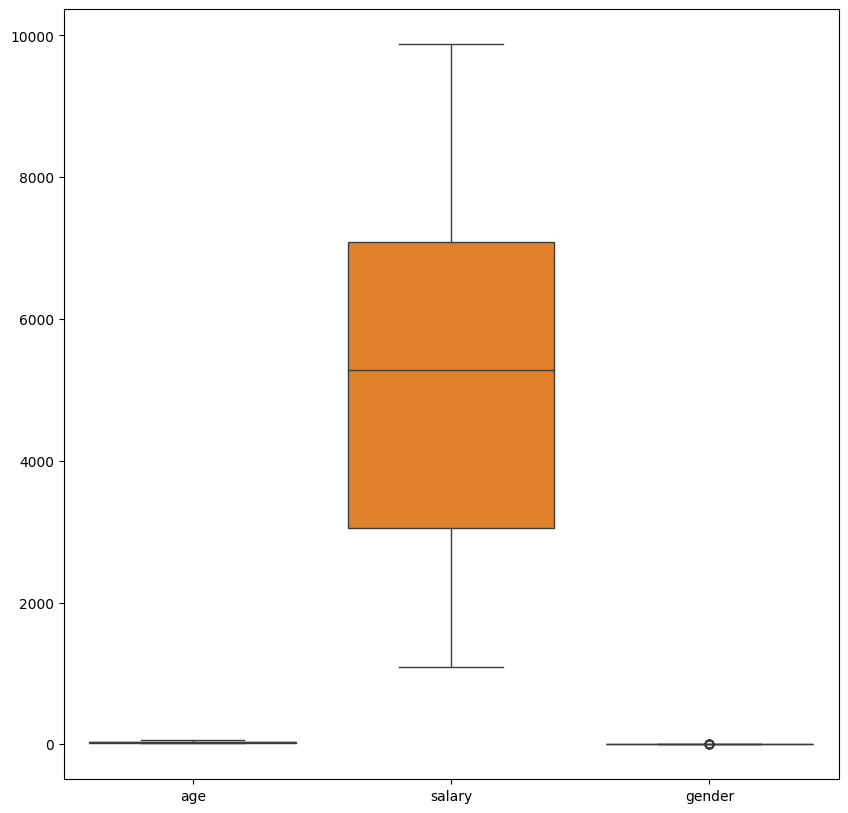

In [13]:
#to find outliers
plt.figure(figsize=(10,10))
sns.boxplot(df)

In [14]:
#confirm outlier using IQR methode
for col in ['age', 'salary']:

    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = df[(df[col] < lower) | (df[col] > upper)]

    print(col, ":", len(outliers), "outliers")

age : 0 outliers
salary : 0 outliers


3. Data Analysis: (Score : 2)
● Filter the data with age >40 and salary<5000 Plot the chart with age and salary
Count the number of people from each place and represent it visually

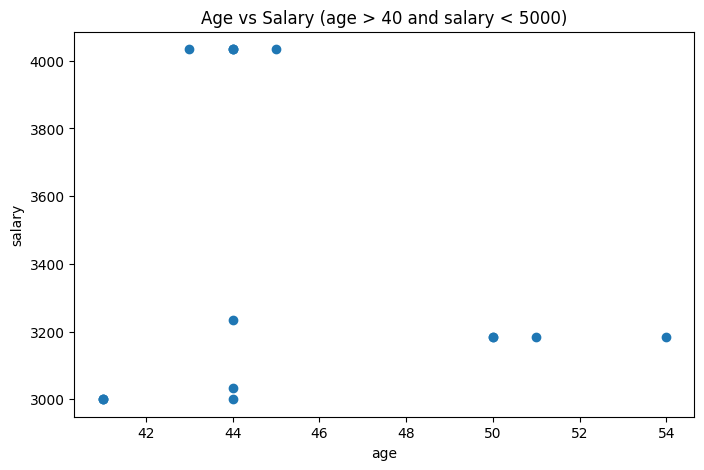

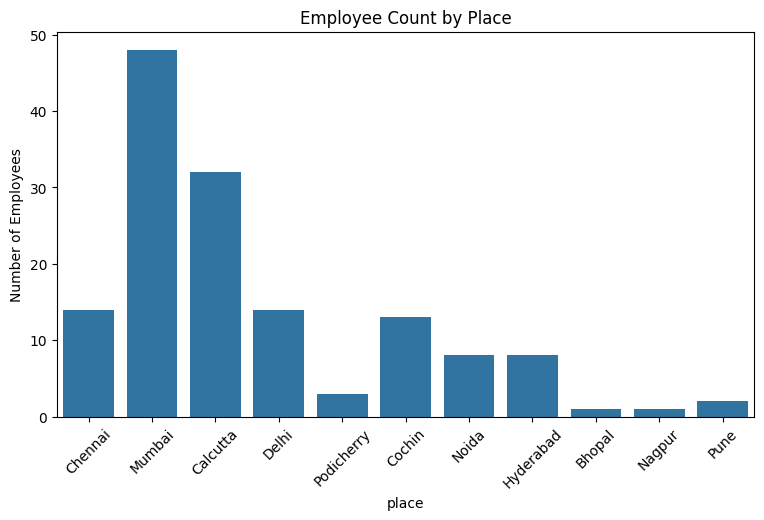

place
Mumbai        48
Calcutta      32
Chennai       14
Delhi         14
Cochin        13
Noida          8
Hyderabad      8
Podicherry     3
Pune           2
Bhopal         1
Nagpur         1
Name: count, dtype: int64


In [21]:
filtered_df = df[(df['age'] > 40) & (df['salary'] < 5000)]
len(filtered_df)
plt.figure(figsize=(8,5))

plt.scatter(filtered_df['age'], filtered_df['salary'])

plt.xlabel('age')
plt.ylabel('salary')
plt.title('Age vs Salary (age > 40 and salary < 5000)')

plt.show()

plt.figure(figsize=(9,5))

sns.countplot(data=df, x='place')

plt.xlabel('place')
plt.ylabel('Number of Employees')
plt.title('Employee Count by Place')

plt.xticks(rotation=45)

plt.show()

place_count = df['place'].value_counts()

print(place_count)


4. Data Encoding: (Score : 2)
● Convert categorical variables into numerical representations using techniques
such as one-hot encoding, label encoding, making them suitable for analysis by
machine learning algorithms.

In [22]:
df.dtypes

,0
company,object
age,float64
salary,float64
place,object
country,object
gender,int64


In [23]:
#Label: TCS	0,Infosys	1,CTS	2
from sklearn.preprocessing import LabelEncoder
categorical_cols = ['company', 'place', 'country']
le = LabelEncoder()

for col in categorical_cols:
    df[col] = le.fit_transform(df[col])
df.head()

,company,age,salary,place,country,gender
0,2,20.0,5283.471074,2,0,0
1,1,30.0,5283.471074,6,0,0
2,2,35.0,2300.000000,1,0,0
3,1,40.0,3000.000000,4,0,0
4,2,23.0,4000.000000,6,0,0


5. Feature Scaling: (Score : 2)
● After the process of encoding, perform the scaling of the features using
standardscaler and minmaxscaler.

In [28]:
# B. MINMAX SCALER
from sklearn.preprocessing import StandardScaler, MinMaxScaler

numerical_cols = ['age', 'salary']

X = df[numerical_cols]

scaler = StandardScaler()

df_standard = df.copy()

df_standard[numerical_cols] = scaler.fit_transform(
    df_standard[numerical_cols]
)


print("\nMinMax Scaled Dataset:")
print(df_standard.head())


MinMax Scaled Dataset:
   company       age    salary  place  country  gender
0        2 -1.419994  0.000000      2        0       0
1        1 -0.228028  0.000000      6        0       0
2        2  0.367955 -1.264122      1        0       0
3        1  0.963938 -0.967526      4        0       0
4        2 -1.062404 -0.543818      6        0       0
